# Exercise 4

In [14]:
import numpy as np
def center(X):
    X_means = np.mean(X,axis=1)[:,np.newaxis]
    X_normalized = X - X_means

    return X_normalized

def compute_pcs(X,lam):
    # create the correlation matrix
    P = float(X.shape[1])
    Cov = 1/P*np.dot(X,X.T) + lam*np.eye(X.shape[0])

    # use numpy function to compute eigenvalues / vectors of correlation matrix
    D,V = np.linalg.eigh(Cov)
    return D,V

In [15]:
X_original = np.loadtxt('2d_span_data.csv', delimiter=',')

In [16]:
X_normalized = center(X_original)

In [17]:
pca = compute_pcs(X_normalized, 0.01)


In [18]:
_, V = pca
V


array([[-0.7630423 , -0.64634856],
       [-0.64634856,  0.7630423 ]])

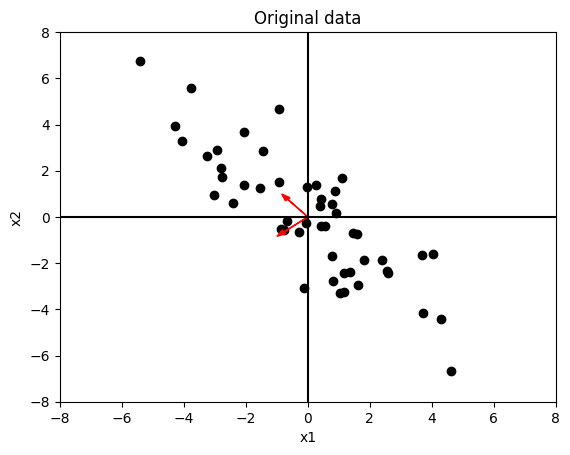

In [61]:
import matplotlib.pyplot as plt 
plt.scatter(X_normalized[0], X_normalized[1],  label='Original data', color="black")
plt.title("Original data")
plt.xlabel("x1")
plt.ylabel("x2")
plt.xlim(-8, 8)
plt.ylim(-8, 8)
plt.arrow(0, 0, V[0, 0], V[1, 0], head_width=0.2, color='red', label='C1')
plt.arrow(0, 0, V[1, 0], V[1, 1], head_width=0.2, color='red', label='C1')
plt.axhline(0, color="black")
plt.axvline(0, color="black")
plt.show()


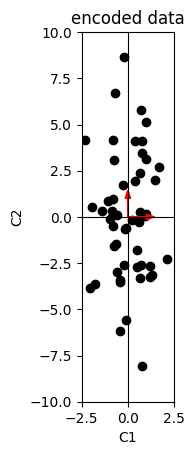

In [60]:
X_encoded = V.T @ X_normalized

plt.scatter(X_encoded[0], X_encoded[1], color="black")
plt.title("encoded data")
plt.xlabel("C1")
plt.ylabel("C2")

plt.arrow(0, 0, 1, 0, head_width=0.3, color='red')
plt.arrow(0, 0, 0, 1, head_width=0.3, color='red')

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().set_aspect('equal') 
plt.xlim(-2.5, 2.5)
plt.ylim(-10, 10)
plt.show()